# Week 11 — Comparing Two Groups (Patients vs Controls)

Most imaging projects end with the same question: **is a measured metric different between two
groups?** (e.g. hippocampal volume in Alzheimer's vs controls). Choosing the **right statistical test**
depends on whether the data are **normally distributed**. This notebook walks the full decision:

1. **Check normality** with the **Shapiro–Wilk** test.
2. Pick the test: **parametric** (two-sample *t*-test) if normal, **non-parametric**
   (**Mann–Whitney / Wilcoxon rank-sum**) if not.
3. Report an **effect size** (Cohen's *d*), not just a *p*-value.
4. Tie back to **power / cohort size** (see `../Week09/CohortSizeDetermination.ipynb`).

We use a continuous metric — **hippocampal volume (mL)** — as the running example.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(1)
plt.rcParams["figure.dpi"] = 110

# Two groups of a continuous metric (hippocampal volume, mL)
control = rng.normal(3.25, 0.30, size=32)                 # roughly normal
patient = rng.normal(2.75, 0.35, size=32)                 # smaller in Alzheimer's
# A deliberately skewed metric, to show when the test choice matters
skewed_ctrl = rng.lognormal(0.2, 0.5, size=32)
skewed_pat = rng.lognormal(0.5, 0.5, size=32)
print(f"control n={control.size}, mean={control.mean():.2f} mL;  patient n={patient.size}, mean={patient.mean():.2f} mL")

control n=32, mean=3.24 mL;  patient n=32, mean=2.71 mL


## 1. Look at the distributions first

Always visualize before testing. Overlapping histograms and a box plot show the group difference and
whether either group looks skewed or has outliers.

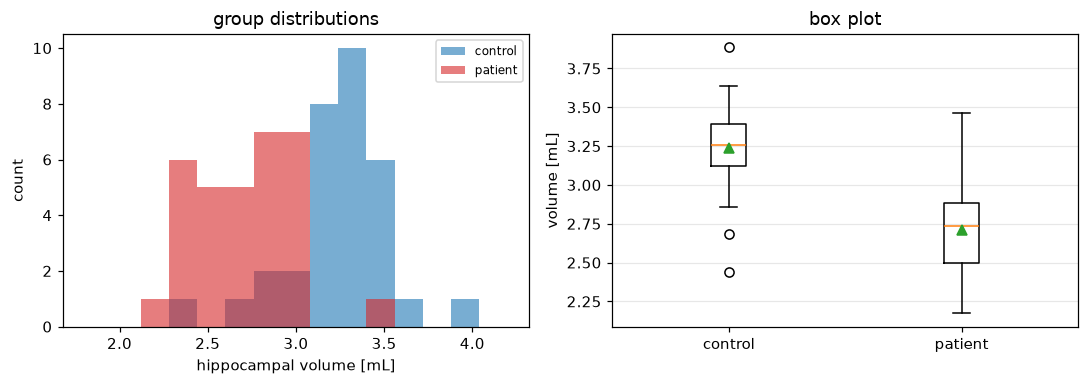

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
bins = np.linspace(1.8, 4.2, 16)
ax[0].hist(control, bins, alpha=0.6, label="control", color="tab:blue")
ax[0].hist(patient, bins, alpha=0.6, label="patient", color="tab:red")
ax[0].set_xlabel("hippocampal volume [mL]"); ax[0].set_ylabel("count")
ax[0].set_title("group distributions"); ax[0].legend(fontsize=8)
ax[1].boxplot([control, patient], tick_labels=["control", "patient"], showmeans=True)
ax[1].set_ylabel("volume [mL]"); ax[1].set_title("box plot"); ax[1].grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

## 2. Test normality: Shapiro–Wilk

The **Shapiro–Wilk** test's null hypothesis is “the data are normal.” If **p > 0.05** we fail to reject
normality (treat as normal); if **p ≤ 0.05** the data are significantly non-normal and a
**non-parametric** test is safer.

In [3]:
def normality(name, x):
    w, p = stats.shapiro(x)
    verdict = "normal" if p > 0.05 else "NON-normal"
    print(f"{name:20s} Shapiro-Wilk W={w:.3f}, p={p:.3f}  ->  {verdict}")
    return p > 0.05

print("Hippocampal volume example:")
n1 = normality("control", control)
n2 = normality("patient", patient)
print("\nSkewed (log-normal) example:")
normality("skewed control", skewed_ctrl)
normality("skewed patient", skewed_pat)

Hippocampal volume example:
control              Shapiro-Wilk W=0.960, p=0.276  ->  normal
patient              Shapiro-Wilk W=0.976, p=0.663  ->  normal

Skewed (log-normal) example:
skewed control       Shapiro-Wilk W=0.976, p=0.673  ->  normal
skewed patient       Shapiro-Wilk W=0.847, p=0.000  ->  NON-normal


np.False_

## 3. Choose and run the test

- **Both groups normal** → two-sample **Welch *t*-test** (`ttest_ind`, unequal variances).
- **Either group non-normal** → **Mann–Whitney U / Wilcoxon rank-sum** (`mannwhitneyu`), which compares
  distributions by rank and makes no normality assumption.

On the (normal) volume data both tests agree; on the **skewed** data the *t*-test can mislead while the
rank test stays valid.

In [4]:
def compare(name, a, b, both_normal):
    t_p = stats.ttest_ind(a, b, equal_var=False).pvalue
    u_p = stats.mannwhitneyu(a, b, alternative="two-sided").pvalue
    chosen = "t-test" if both_normal else "Mann-Whitney"
    chosen_p = t_p if both_normal else u_p
    print(f"{name}:")
    print(f"   Welch t-test p = {t_p:.4f}")
    print(f"   Mann-Whitney p = {u_p:.4f}")
    print(f"   -> use {chosen} (p = {chosen_p:.4f}) {'[significant]' if chosen_p < 0.05 else '[n.s.]'}\n")

compare("Hippocampal volume (normal)", control, patient, n1 and n2)
compare("Skewed metric (non-normal)", skewed_ctrl, skewed_pat, False)

Hippocampal volume (normal):
   Welch t-test p = 0.0000
   Mann-Whitney p = 0.0000
   -> use t-test (p = 0.0000) [significant]

Skewed metric (non-normal):
   Welch t-test p = 0.0097
   Mann-Whitney p = 0.0229
   -> use Mann-Whitney (p = 0.0229) [significant]



## 4. Effect size and power

A *p*-value says *whether* there is a difference; the **effect size** says *how big*. **Cohen's**
$d=(\bar x_1-\bar x_2)/s_\text{pooled}$ standardizes the mean difference. Feeding that $d$ into the
power formula from `CohortSizeDetermination.ipynb` tells you the **cohort size** needed for 80% power
— useful to justify your sample or to plan a follow-up.

In [5]:
def cohens_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / sp

def n_per_group(d, alpha=0.05, power=0.80):
    za = stats.norm.ppf(1 - alpha / 2); zb = stats.norm.ppf(power)
    return int(np.ceil(2 * (za + zb) ** 2 / d ** 2))

d = cohens_d(control, patient)
print(f"Cohen's d = {d:.2f}  ({'large' if abs(d) >= 0.8 else 'medium' if abs(d) >= 0.5 else 'small'} effect)")
print(f"n needed per group for 80% power at alpha=0.05: {n_per_group(abs(d))}")
print(f"(we used n = {control.size} per group)")

Cohen's d = 1.90  (large effect)
n needed per group for 80% power at alpha=0.05: 5
(we used n = 32 per group)


## Takeaways — the decision in one line

> **Visualize → Shapiro–Wilk → (normal?) *t*-test : Mann–Whitney → report effect size → check power.**

- **Shapiro–Wilk** decides parametric vs non-parametric; when in doubt, the **rank-based** test is the
  conservative choice.
- Always pair the *p*-value with an **effect size** (Cohen's *d*) — significance ≠ importance.
- The same effect size feeds **power / cohort-size** planning (Week 09 notebook).
- For **> 2 groups** use ANOVA / Kruskal–Wallis; for **paired** measurements (e.g. same subject
  pre/post) use the paired *t*-test / Wilcoxon signed-rank.